**[🏠 Course Home](00_START_HERE.ipynb)** | **📖 [Conceptual](../conceptual/14_marginal_likelihood_and_model_comparison.ipynb)** | **🐍 [Python](../python/14_marginal_likelihood_and_model_comparison.ipynb)** | **⬅️ [Prev: Ch 13: Hierarchical Models & Shrinkage](13_hierarchical_models_and_partial_pooling.ipynb)** | **➡️ [Next: Ch 15: Dynamic Memory & Decay (γ)](15_calibrating_bayesian_decay_and_memory.ipynb)**

*🧭 Part III: Applied Modeling, Regression, Hierarchy & Model Comparison — Chapter 14 of 22*

---

# Chapter 14: Likelihood vs. Marginal Likelihood, Occam's Razor & Model Comparison (R Track)
### *Interactive Laboratory: Evidence Integration, Bayes Factors & Cross-Validation in R*

---

## 🧭 The Learning Progression
1. **Part 1: Likelihood vs. Marginal Likelihood**: Calculate point likelihood
versus Bayesian evidence for coin tosses by exact analytical integration.
2. **Part 2: The Probability Budget & Occam Factor**: Visualize how model
complexity dilutes prior predictive density across dataset space.
3. **Part 3: Bayes Factors & Lindley's Paradox**: Observe how diffuse priors
inadvertently penalize hypotheses in Bayesian hypothesis testing.
4. **Part 4: Structural Attribution vs. Out-of-Sample Prediction**: Fit
polynomial models (Degrees 1, 2, 3, 7) and contrast Marginal Likelihood with
Leave-One-Out Cross-Validation (LOO-CV).
5. **Part 5: 3-Tier Scaffolding Exercises**: Test your understanding with
hands-on computational problems from guided calculations to production code.


---

## Part 1: What Is Marginal Likelihood, and How Does It Differ from Likelihood?

In parameter estimation, we evaluate the **point likelihood** $P(\mathcal{D}
\mid \theta, \mathcal{M})$: the probability of the data given a single, fixed
coordinate $\theta$. Maximizing this function over $\theta$ always rewards
flexibility, leading to severe overfitting.

In Bayesian model comparison, we evaluate the **Marginal Likelihood** (or
**Bayesian Evidence**) $P(\mathcal{D} \mid \mathcal{M})$, which integrates the
likelihood across all possible parameter values weighted by the prior:

$$P(\mathcal{D} \mid \mathcal{M}) = \int_{\Theta} P(\mathcal{D} \mid \theta, \mathcal{M}) P(\theta \mid \mathcal{M}) \, d\theta$$

Because this is a definite integral across the parameter manifold $\Theta$, the
parameter vector $\theta$ disappears entirely. The resulting scalar represents
the average predictive performance of the model architecture itself.

### Worked Example: Fair Coin vs. Unknown Bias ($n=10, k=7$)
* **Model $\mathcal{M}_0$ (Fair Coin)**: Fixed parameter $p = 0.5$.
$$P(\mathcal{D} \mid \mathcal{M}_0) = \binom{10}{7} (0.5)^7 (0.5)^3 =
\frac{120}{1024} \approx 0.117188$$
* **Model $\mathcal{M}_1$ (Biased Coin)**: Prior $p \sim \text{Beta}(1, 1) =
  \text{Uniform}(0, 1)$.
$$P(\mathcal{D} \mid \mathcal{M}_1) = \int_0^1 \binom{10}{7} p^7 (1 - p)^3 \cdot
1 \, dp = \frac{1}{11} \approx 0.090909$$
* Notice that while the MLE $\hat{p} = 0.7$ gives peak likelihood $\approx
  0.2668$,
the *marginal likelihood* is only $0.0909$, giving $BF_{01} \approx 1.289$ in
favor of the simple fair coin!


Model M0 (Fair Coin, p=0.5):        P(D | M0) = 0.117188


M1 (MLE p=0.7):       P(D | p=0.7) = 0.266828


M1 (Marginal Evidence):  P(D | M1) = 0.090909


Bayes Factor BF_01: 1.289x in favor of Fair Coin!


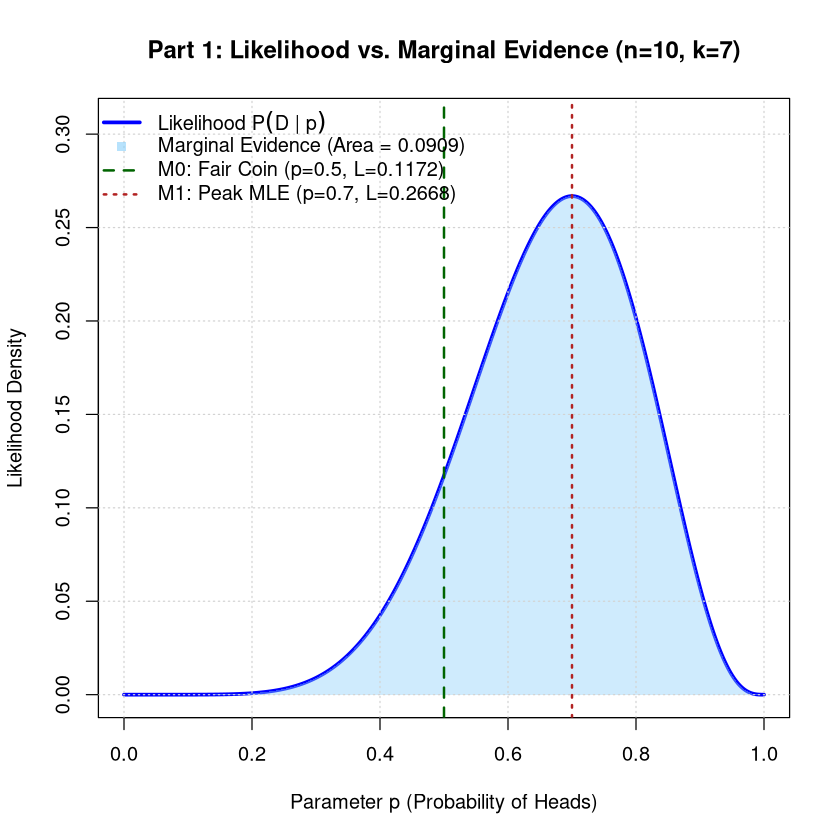

In [1]:
# Part 1: Point Likelihood vs. Marginal Likelihood in Base R
n <- 10; k <- 7
p_grid <- seq(0, 1, length.out = 500)
likelihood_grid <- dbinom(k, n, p_grid)

# Model Calculations
lik_m0 <- dbinom(k, n, 0.5)
mle_p <- k / n
lik_m1_mle <- dbinom(k, n, mle_p)
marg_lik_m1 <- 1 / (n + 1)  # Exact Beta-Binomial integral for Beta(1, 1)
bf_01 <- lik_m0 / marg_lik_m1

# Visualization
plot(p_grid, likelihood_grid, type = 'l', lwd = 3, col = 'blue',
     main = 'Part 1: Likelihood vs. Marginal Evidence (n=10, k=7)',
     xlab = 'Parameter p (Probability of Heads)', ylab = 'Likelihood Density',
     xlim = c(0, 1), ylim = c(0, max(likelihood_grid) * 1.15))
polygon(c(p_grid, rev(p_grid)), c(likelihood_grid, rep(0, length(p_grid))),
        col = rgb(0.53, 0.81, 0.98, 0.4), border = NA)
grid()

abline(v = 0.5, col = 'darkgreen', lty = 2, lwd = 2)
abline(v = mle_p, col = 'firebrick', lty = 3, lwd = 2)

legend('topleft', bty = 'n', lwd = c(3, NA, 2, 2),
       lty = c(1, NA, 2, 3), pch = c(NA, 15, NA, NA),
       col = c('blue', rgb(0.53, 0.81, 0.98, 0.6), 'darkgreen', 'firebrick'),
       legend = c(expression(Likelihood ~ P(D ~ '|' ~ p)),
                  sprintf('Marginal Evidence (Area = %.4f)', marg_lik_m1),
                  sprintf('M0: Fair Coin (p=0.5, L=%.4f)', lik_m0),
                  sprintf('M1: Peak MLE (p=0.7, L=%.4f)', lik_m1_mle)))

cat(sprintf('Model M0 (Fair Coin, p=0.5):        P(D | M0) = %.6f\n', lik_m0))
cat(sprintf('M1 (MLE p=0.7):       P(D | p=0.7) = %.6f\n', lik_m1_mle))
cat(sprintf('M1 (Marginal Evidence):  P(D | M1) = %.6f\n', marg_lik_m1))
cat(sprintf('Bayes Factor BF_01: %.3fx in favor of Fair Coin!\n', bf_01))

---

## Part 2: The Automatic Bayesian Occam's Razor (The Gambling Budget Analogy)

Why does Bayesian inference automatically penalize complexity without ad-hoc
penalty terms like AIC ($2k$) or BIC ($k \ln n$)?

### The Conservation of Probability
Every valid probabilistic model $\mathcal{M}$ defines a probability
distribution over all possible datasets $\mathcal{D}$:

$$\sum_{\mathcal{D}} P(\mathcal{D} \mid \mathcal{M}) = 1 \quad \text{or} \quad \int P(\mathcal{D} \mid \mathcal{M}) \, d\mathcal{D} = 1$$

Each model receives **exactly the same total probability budget: 1.0.**
* **Simple Model $\mathcal{M}_1$**: Spends its entire budget betting on a
compact domain of simple datasets. If the true data lands in this region,
the predictive density $P(\mathcal{D} \mid \mathcal{M}_1)$ is high.
* **Complex Model $\mathcal{M}_2$**: Spreads its budget across a vast universe
of possible datasets. Its density $P(\mathcal{D} \mid \mathcal{M}_2)$ is
diluted everywhere.

### The Occam Factor via Laplace Approximation
Around the posterior mode $\hat{\theta}$, the evidence decomposes as:

$$P(\mathcal{D} \mid \mathcal{M}) \approx P(\mathcal{D} \mid \hat{\theta}, \mathcal{M}) \times \underbrace{\frac{\Delta \theta_{\text{post}}}{\Delta \theta_{\text{prior}}}}_{\text{Occam Factor } < 1}$$

Where $\Delta \theta_{\text{post}}$ is the posterior uncertainty volume and
$\Delta \theta_{\text{prior}}$ is the prior parameter volume.


Density at y=1.2: M1=0.1931, M2=0.0652


Bayes Factor BF_12: 2.96x in favor of M1!


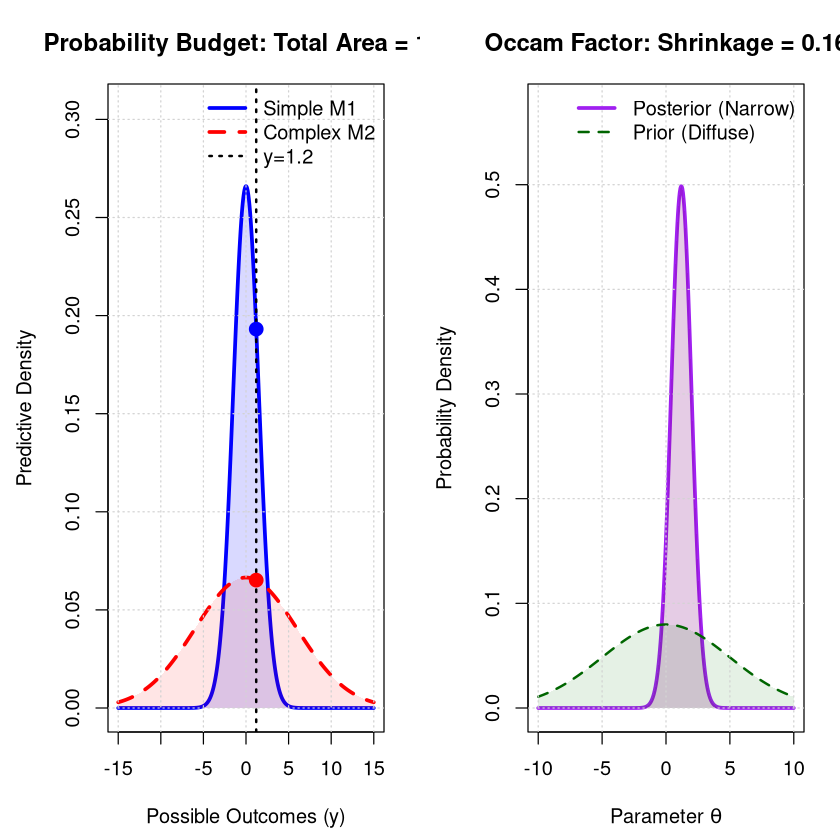

In [2]:
# Part 2: Visualizing the Probability Budget & The Occam Factor in Base R
par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3.5, 1.5))

y_domain <- seq(-15, 15, length.out = 600)
pdf_m1 <- dnorm(y_domain, mean = 0, sd = 1.5)
pdf_m2 <- dnorm(y_domain, mean = 0, sd = 6.0)
y_obs <- 1.2
p_obs_m1 <- dnorm(y_obs, 0, 1.5)
p_obs_m2 <- dnorm(y_obs, 0, 6.0)
bf_12_budget <- p_obs_m1 / p_obs_m2

# Subplot 1: Probability Budget
plot(y_domain, pdf_m1, type = 'l', col = 'blue', lwd = 3,
     main = 'Probability Budget: Total Area = 1.0',
     xlab = 'Possible Outcomes (y)', ylab = 'Predictive Density',
     ylim = c(0, max(pdf_m1) * 1.15))
polygon(c(y_domain, rev(y_domain)), c(pdf_m1, rep(0, length(y_domain))),
        col = rgb(0, 0, 1, 0.15), border = NA)
lines(y_domain, pdf_m2, col = 'red', lty = 2, lwd = 3)
polygon(c(y_domain, rev(y_domain)), c(pdf_m2, rep(0, length(y_domain))),
        col = rgb(1, 0, 0, 0.10), border = NA)
grid()
abline(v = y_obs, col = 'black', lty = 3, lwd = 2)
points(c(y_obs, y_obs), c(p_obs_m1, p_obs_m2), pch = 19,
       col = c('blue', 'red'), cex = 1.5)

legend('topright', bty = 'n', lwd = c(3, 3, 2), lty = c(1, 2, 3),
       col = c('blue', 'red', 'black'),
       legend = c('Simple M1', 'Complex M2', sprintf('y=%.1f', y_obs)))

# Subplot 2: Occam Factor Shrinkage
theta_grid <- seq(-10, 10, length.out = 400)
prior_pdf <- dnorm(theta_grid, 0, 5.0)
post_pdf <- dnorm(theta_grid, 1.2, 0.8)
occam_factor <- 0.8 / 5.0

plot(theta_grid, post_pdf, type = 'l', col = 'purple', lwd = 3,
     main = sprintf('Occam Factor: Shrinkage = %.2f', occam_factor),
     xlab = expression(Parameter ~ theta), ylab = 'Probability Density',
     ylim = c(0, max(post_pdf) * 1.15))
polygon(c(theta_grid, rev(theta_grid)), c(post_pdf, rep(0, length(theta_grid))),
        col = rgb(0.5, 0, 0.5, 0.2), border = NA)
lines(theta_grid, prior_pdf, col = 'darkgreen', lty = 2, lwd = 2)
polygon(c(theta_grid, rev(theta_grid)),
        c(prior_pdf, rep(0, length(theta_grid))),
        col = rgb(0, 0.5, 0, 0.1), border = NA)
grid()

legend('topright', bty = 'n', lwd = c(3, 2), lty = c(1, 2),
       col = c('purple', 'darkgreen'),
       legend = c('Posterior (Narrow)', 'Prior (Diffuse)'))

par(mfrow = c(1, 1))

cat(sprintf('Density at y=%.1f: M1=%.4f, M2=%.4f\n', y_obs, p_obs_m1, p_obs_m2))
cat(sprintf('Bayes Factor BF_12: %.2fx in favor of M1!\n', bf_12_budget))

---

## Part 3: Bayes Factors ($BF_{12}$) & Lindley's Paradox

The Bayes Factor updates prior model odds to posterior model odds:

$$\frac{P(\mathcal{M}_1 \mid \mathcal{D})}{P(\mathcal{M}_2 \mid \mathcal{D})} = \frac{P(\mathcal{M}_1)}{P(\mathcal{M}_2)} \times BF_{12}, \quad BF_{12} = \frac{P(\mathcal{D} \mid \mathcal{M}_1)}{P(\mathcal{D} \mid \mathcal{M}_2)}$$

### Harold Jeffreys' Scale of Evidence
* $BF_{12} \in [1, 3]$: Anecdotal / weak evidence
* $BF_{12} \in [3, 10]$: Substantial evidence
* $BF_{12} \in [10, 30]$: Strong evidence
* $BF_{12} > 100$: Decisive evidence

### Lindley's Paradox
Consider testing $H_0: \theta = 0$ against $H_1: \theta \sim \mathcal{N}(0,
\sigma_0^2)$
with $y_i \sim \mathcal{N}(\theta, \sigma^2)$.
When $z = \frac{\bar{y}}{\sigma / \sqrt{n}} = 2.58$, the frequentist $p$-value
is $p \approx 0.01$ (rejects $H_0$).

However, the analytical Bayes Factor in favor of $H_0$ is:

$$BF_{01} = \sqrt{1 + \frac{n \sigma_0^2}{\sigma^2}} \exp\left(-\frac{z^2}{2} \cdot \frac{\frac{n\sigma_0^2}{\sigma^2}}{1 + \frac{n\sigma_0^2}{\sigma^2}}\right)$$

As prior standard deviation $\sigma_0 \to \infty$, $BF_{01} \to \infty$!
**An arbitrarily diffuse prior guarantees that the null hypothesis will win,
even when the empirical evidence against the null is statistically
significant.**


p-value: 0.0099 (Rejects H0 at alpha=0.01)


BF_01 at sigma_0 = 1.0:   0.268 (Favors H1)


BF_01 at sigma_0 = 10.0:  0.375 (Weak)


BF_01 at sigma_0 = 100.0: 3.559 (Favors H0!)


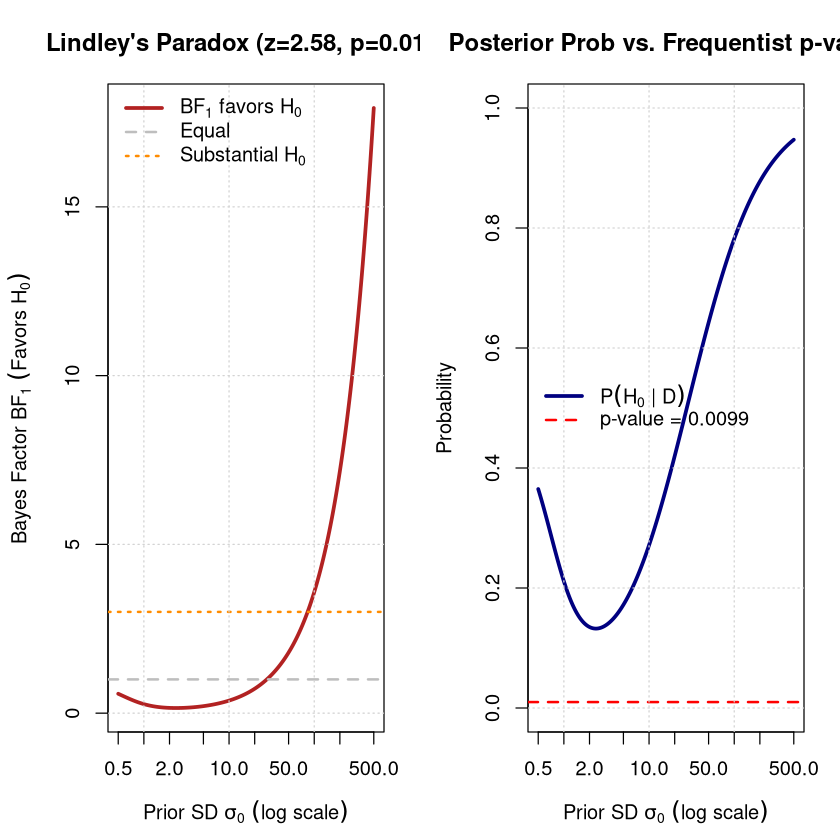

In [3]:
# Part 3: Simulating Lindley's Paradox in Base R
par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3.5, 1.5))

z <- 2.58
n <- 100
sigma_obs <- 10.0
p_value <- 2.0 * (1.0 - pnorm(z))

sigma_0_values <- exp(seq(log(0.5), log(500.0), length.out = 300))
tau_sq <- (n * (sigma_0_values^2)) / (sigma_obs^2)
bf_01 <- sqrt(1.0 + tau_sq) * exp(-0.5 * (z^2) * (tau_sq / (1.0 + tau_sq)))
post_prob_h0 <- bf_01 / (1.0 + bf_01)

# Subplot 1: Bayes Factor BF_01 vs Prior SD
plot(sigma_0_values, bf_01, type = 'l', log = 'x', col = 'firebrick', lwd = 3,
     main = sprintf("Lindley's Paradox (z=%.2f, p=%.3f)", z, p_value),
     xlab = expression(Prior ~ SD ~ sigma[0] ~ (log ~ scale)),
     ylab = expression(Bayes ~ Factor ~ BF[01] ~ (Favors ~ H[0])))
abline(h = 1.0, col = 'gray', lty = 2, lwd = 2)
abline(h = 3.0, col = 'darkorange', lty = 3, lwd = 2)
grid()

legend('topleft', bty = 'n', lwd = c(3, 2, 2), lty = c(1, 2, 3),
       col = c('firebrick', 'gray', 'darkorange'),
       legend = c(expression(BF[01] ~ favors ~ H[0]),
                  'Equal', expression(Substantial ~ H[0])))

# Subplot 2: Posterior Prob vs p-value
plot(sigma_0_values, post_prob_h0, type = 'l', log = 'x', col = 'navy', lwd = 3,
     main = 'Posterior Prob vs. Frequentist p-value',
     xlab = expression(Prior ~ SD ~ sigma[0] ~ (log ~ scale)),
     ylab = 'Probability', ylim = c(0, 1))
abline(h = p_value, col = 'red', lty = 2, lwd = 2)
grid()

legend('left', bty = 'n', lwd = c(3, 2), lty = c(1, 2),
       col = c('navy', 'red'),
       legend = c(expression(P(H[0] ~ '|' ~ D)),
                  sprintf('p-value = %.4f', p_value)))

par(mfrow = c(1, 1))

cat(sprintf('p-value: %.4f (Rejects H0 at alpha=0.01)\n', p_value))
idx1 <- which.min(abs(sigma_0_values - 1.0))
idx10 <- which.min(abs(sigma_0_values - 10.0))
idx100 <- which.min(abs(sigma_0_values - 100.0))
cat(sprintf('BF_01 at sigma_0 = 1.0:   %.3f (Favors H1)\n', bf_01[idx1]))
cat(sprintf('BF_01 at sigma_0 = 10.0:  %.3f (Weak)\n', bf_01[idx10]))
cat(sprintf('BF_01 at sigma_0 = 100.0: %.3f (Favors H0!)\n', bf_01[idx100]))

---

## Part 4: Bayes Factors vs. Out-of-Sample Cross-Validation (LOO-CV)

Two fundamentally different questions guide model comparison:
1. **Hypothesis Testing / Attribution ($\mathcal{M}$-Closed)**: Which model
reflects the true physical process? Evaluated via **Marginal Likelihood**
$\ln P(\mathcal{D} \mid \mathcal{M})$.
2. **Predictive Generalization ($\mathcal{M}$-Open)**: Which model best predicts
unseen future observations? Evaluated via **Leave-One-Out Cross-Validation**
(LOO-CV) and expected log pointwise predictive density (ELPD).

### Polynomial Test Suite (Degree 1, 2, 3, 7)
We simulate $N = 30$ observations from a quadratic ground truth:
$$y = 1.0 - 1.5x + 0.8x^2 + \epsilon, \quad \epsilon \sim \mathcal{N}(0, 0.5^2)$$

For Bayesian linear regression $\mathbf{y} \sim
\mathcal{N}(\mathbf{X}\boldsymbol{\beta}, \sigma^2 \mathbf{I})$
with conjugate prior $\boldsymbol{\beta} \sim \mathcal{N}(\mathbf{0}, \sigma_0^2
\mathbf{I})$,
the marginal likelihood is exact:

$$\ln P(\mathbf{y} \mid \mathbf{X}, \mathcal{M}) = -\frac{N}{2}\ln(2\pi) - \frac{N-p}{2}\ln(\sigma^2) - \frac{p}{2}\ln(\sigma_0^2) - \frac{1}{2}\ln|\boldsymbol{\Sigma}_n^{-1}| - \frac{1}{2}\text{SSE}_{\text{post}}$$

And the LOO-CV residual shortcut via leverage diagonal $h_{ii}$ is:
$$r_{i, -i} = \frac{y_i - \hat{y}_i}{1 - h_{ii}}$$


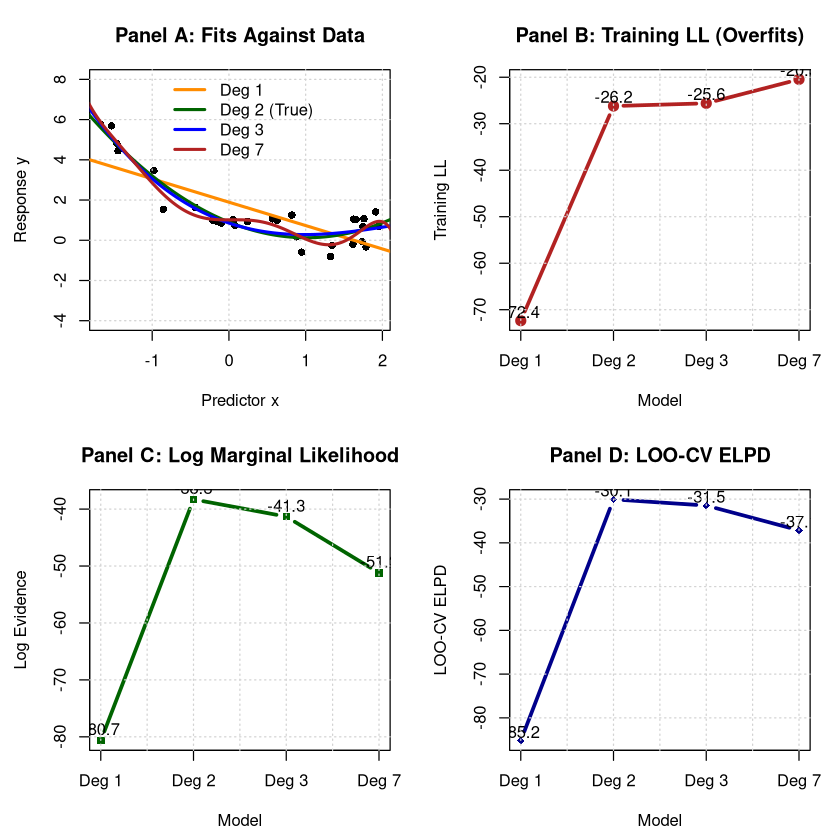

In [4]:
# Part 4: Polynomial Model Suite Simulation in Base R
set.seed(42)
N <- 30
x <- runif(N, -2, 2)
sigma_noise <- 0.5
sigma0 <- 2.0
y <- 1.0 - 1.5 * x + 0.8 * (x^2) + rnorm(N, 0, sigma_noise)

degrees <- c(1, 2, 3, 7)
train_lls <- numeric(length(degrees))
marg_liks <- numeric(length(degrees))
loo_elpds <- numeric(length(degrees))

x_plot <- seq(-2.2, 2.2, length.out = 300)
fitted_curves <- list()

for (idx in seq_along(degrees)) {
  d <- degrees[idx]
  X <- outer(x, 0:d, '^')
  X_plot <- outer(x_plot, 0:d, '^')
  p <- d + 1
  
  XtX <- t(X) %*% X
  Xty <- t(X) %*% y
  Sigma_post_inv <- diag(p) / (sigma0^2) + XtX / (sigma_noise^2)
  Sigma_post <- solve(Sigma_post_inv)
  mu_post <- as.vector(Sigma_post %*% (Xty / (sigma_noise^2)))
  
  # Training LL
  y_pred <- as.vector(X %*% mu_post)
  res <- y - y_pred
  train_lls[idx] <- (-0.5 * N * log(2 * pi * sigma_noise^2)
                     - 0.5 * sum(res^2) / (sigma_noise^2))
  
  # Exact Marginal Likelihood
  logdet_inv <- determinant(Sigma_post_inv, logarithm = TRUE)$modulus[1]
  quad <- sum(res^2) / (sigma_noise^2) + sum(mu_post^2) / (sigma0^2)
  marg_liks[idx] <- (-0.5 * N * log(2 * pi)
                     - 0.5 * (N - p) * log(sigma_noise^2)
                     - 0.5 * p * log(sigma0^2)
                     - 0.5 * logdet_inv - 0.5 * quad)
                     
  # LOO-CV
  H <- X %*% Sigma_post %*% t(X) / (sigma_noise^2)
  h_diag <- diag(H)
  loo_errors <- (y - y_pred) / (1.0 - h_diag)
  loo_elpds[idx] <- (-0.5 * N * log(2 * pi * sigma_noise^2)
                     - 0.5 * sum(loo_errors^2) / (sigma_noise^2))
  
  fitted_curves[[idx]] <- as.vector(X_plot %*% mu_post)
}

# 4-Panel Visualization
par(mfrow = c(2, 2), mar = c(4.5, 4.5, 3.5, 1.5))

# Panel 1: Curves
plot(x, y, pch = 16, col = 'black', ylim = c(-4, 8),
     main = 'Panel A: Fits Against Data',
     xlab = 'Predictor x', ylab = 'Response y')
grid()
colors <- c('darkorange', 'darkgreen', 'blue', 'firebrick')
for (idx in seq_along(degrees)) {
  lines(x_plot, fitted_curves[[idx]], col = colors[idx], lwd = 2.5)
}
legend('top', bty = 'n', lwd = 2.5, col = colors,
       legend = c('Deg 1', 'Deg 2 (True)', 'Deg 3', 'Deg 7'))

# Panel 2: Training LL
deg_labels <- paste('Deg', degrees)
plot(1:4, train_lls, type = 'b', pch = 19, col = 'firebrick', lwd = 3,
     xaxt = 'n',
     main = 'Panel B: Training LL (Overfits)',
     xlab = 'Model', ylab = 'Training LL')
axis(1, at = 1:4, labels = deg_labels)
text(1:4, train_lls + 2, labels = sprintf('%.1f', train_lls))
grid()

# Panel 3: Log Marginal Likelihood
plot(1:4, marg_liks, type = 'b', pch = 15, col = 'darkgreen', lwd = 3,
     xaxt = 'n',
     main = 'Panel C: Log Marginal Likelihood',
     xlab = 'Model', ylab = 'Log Evidence')
axis(1, at = 1:4, labels = deg_labels)
text(1:4, marg_liks + 2, labels = sprintf('%.1f', marg_liks))
grid()

# Panel 4: LOO-CV
plot(1:4, loo_elpds, type = 'b', pch = 18, col = 'darkblue', lwd = 3,
     xaxt = 'n', main = 'Panel D: LOO-CV ELPD',
     xlab = 'Model', ylab = 'LOO-CV ELPD')
axis(1, at = 1:4, labels = deg_labels)
text(1:4, loo_elpds + 2, labels = sprintf('%.1f', loo_elpds))
grid()

par(mfrow = c(1, 1))

---

## Part 5: Check Your Understanding (3-Tier Scaffolding Exercises)

Sharpen your mathematical intuition and hands-on skills with three structured
computational challenges.

---

### 🟢 Tier 1 (Guided Calculation): Point Likelihood vs. Evidence for Coin Flips

**Scenario**: You flip an unknown physical coin $n = 10$ times and observe
$k = 6$ heads. You want to test whether the coin is fair or biased:
* **Model $\mathcal{M}_0$ (Fair Coin)**: $p = 0.5$ exactly (0 free parameters).
* **Model $\mathcal{M}_1$ (Unknown Bias)**: $p \sim \text{Beta}(1, 1) =
  \text{Uniform}(0, 1)$ (1 free parameter).

**Your Task**:
1. Calculate the point likelihood of $\mathcal{M}_0$ at $p = 0.5$.
2. Calculate the maximum likelihood of $\mathcal{M}_1$ at the MLE $\hat{p} =
   0.6$.
3. Calculate the true marginal likelihood of $\mathcal{M}_1$ by evaluating the
Beta integral: $P(\mathcal{D} \mid \mathcal{M}_1) = \frac{1}{n+1}$.
4. Compute the Bayes Factor $BF_{01} = \frac{P(\mathcal{D} \mid
   \mathcal{M}_0)}{P(\mathcal{D} \mid \mathcal{M}_1)}$.


In [5]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here (Base R)
# ============================================================
n <- 10; k <- 6

# 1. Point likelihood of M0 (p = 0.5)
# lik_m0 <- ...

# 2. Peak likelihood of M1 at MLE (p = 0.6)
# lik_m1_mle <- ...

# 3. Marginal likelihood of M1 integrated over Beta(1, 1)
# marg_lik_m1 <- ...

# 4. Bayes factor BF_01
# bf_01 <- ...

# cat(sprintf("M0 Likelihood:      %.6f\n", lik_m0))
# cat(sprintf("M1 MLE Likelihood:  %.6f\n", lik_m1_mle))
# cat(sprintf("M1 Evidence:        %.6f\n", marg_lik_m1))
# cat(sprintf("Bayes Factor BF_01: %.3f\n", bf_01))

<details>
<summary><b>🔍 Reveal Solution & Mathematical Explanation</b></summary>

### Mathematical Derivation & Exact Values

1. **Model $\mathcal{M}_0$ (Fair Coin)**:
$$P(\mathcal{D} \mid \mathcal{M}_0) = \binom{10}{6} (0.5)^6 (0.5)^4 = 210 \times
\frac{1}{1024} = \frac{210}{1024} \approx 0.205078$$

2. **Model $\mathcal{M}_1$ at MLE ($\hat{p} = 0.6$)**:
$$P(\mathcal{D} \mid \hat{p}=0.6, \mathcal{M}_1) = \binom{10}{6} (0.6)^6 (0.4)^4
= 210 \times 0.046656 \times 0.0256 \approx 0.250823$$

3. **Model $\mathcal{M}_1$ Marginal Likelihood (Bayesian Evidence)**:
$$P(\mathcal{D} \mid \mathcal{M}_1) = \int_0^1 \binom{10}{6} p^6 (1 - p)^4 \cdot
1 \, dp = \binom{10}{6} \frac{6! \times 4!}{11!} = \frac{1}{11} \approx
0.090909$$

4. **Bayes Factor $BF_{01}$**:
$$BF_{01} = \frac{P(\mathcal{D} \mid \mathcal{M}_0)}{P(\mathcal{D} \mid
\mathcal{M}_1)} = \frac{210 / 1024}{1 / 11} = \frac{2310}{1024} \approx 2.256$$

```python
# Complete Solution Verification
import scipy.stats as stats
import scipy.special as special

n, k = 10, 6
lik_m0 = stats.binom.pmf(k, n, 0.5)
lik_m1_mle = stats.binom.pmf(k, n, k / n)
marg_lik_m1 = special.comb(n, k) * special.beta(k + 1, n - k + 1)
bf_01 = lik_m0 / marg_lik_m1

print(f"M0 Likelihood:      {lik_m0:.6f}")
print(f"M1 MLE Likelihood:  {lik_m1_mle:.6f}")
print(f"M1 Evidence:        {marg_lik_m1:.6f}")
print(f"Bayes Factor BF_01: {bf_01:.3f}x in favor of Fair Coin")
```

**Key Insight**: Even though the peak likelihood of $\mathcal{M}_1$ ($0.2508$)
beats the fair coin ($0.2051$), the simple fair-coin hypothesis $\mathcal{M}_0$
wins the model comparison ($BF_{01} \approx 2.26$). Observing 6 heads out of 10
is perfectly consistent with fair noise; it is insufficient evidence to pay the
Occam penalty for a free parameter!
</details>


---

### 🟡 Tier 2 (Application): Visualizing the Occam Factor & Lindley's Paradox

**Scenario**: A research team conducts a precision sensor experiment.
* Measurement noise $\sigma = 10.0$, sample size $n = 100$.
* Standard error $SE = \sigma / \sqrt{n} = 1.0$.
* The observed sample mean is $\bar{y} = 2.0$, yielding $z = 2.0$.
* The frequentist two-sided $p$-value is $p \approx 0.0455 < 0.05$
  (statistically significant!).

The team wants to test $\mathcal{M}_0: \theta = 0$ against $\mathcal{M}_1:
\theta \sim \mathcal{N}(0, \sigma_0^2)$.
One team member suggests setting $\sigma_0 = 100$ to be "unbiased and
objective."

**Your Task**:
Compute and tabulate:
1. The Occam Factor shrinkage $\approx \frac{1}{\sqrt{1 + \sigma_0^2}}$.
2. The Bayes Factor $BF_{01} = \frac{P(\bar{y} \mid \mathcal{M}_0)}{P(\bar{y}
   \mid \mathcal{M}_1)}$.
Across $\sigma_0 \in [1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0]$.
Explain at what prior width the evidence flips from favoring the alternative
to favoring the null.


In [6]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here (Base R)
# ============================================================
z <- 2.0  # Frequentist z-score (p = 0.0455)
sigma_0_list <- c(1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0)

# For each s0 in sigma_0_list:
#   occam_factor <- 1.0 / sqrt(1.0 + s0^2)
#   bf_01 <- sqrt(1.0 + s0^2) * exp(-0.5 * (z^2) * (s0^2 / (1.0 + s0^2)))
#   cat(sprintf(...))

<details>
<summary><b>🔍 Reveal Solution & Tabulated Output</b></summary>

```python
# Complete Solution Execution
import numpy as np

z = 2.0
sigma_0_list = [1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0]

print(f"{'Prior SD':<10} | {'Occam':<10} | {'BF_01':<12} | {'Favored Model'}")
print("-" * 55)

for s0 in sigma_0_list:
    tau_sq = s0**2
    occam = 1.0 / np.sqrt(1.0 + tau_sq)
    term = tau_sq / (1.0 + tau_sq)
    bf_01 = np.sqrt(1.0 + tau_sq) * np.exp(-0.5 * (z**2) * term)
    
    if bf_01 < 1.0:
        verdict = f"Alternative (BF_10={1.0/bf_01:.2f}x)"
    else:
        verdict = f"Null (BF_01={bf_01:.2f}x)"
        
    print(f"{s0:<10.1f} | {occam:<10.4f} | {bf_01:<12.3f} | {verdict}")
```

### Tabulated Output
```
Prior SD   | Occam      | BF_01        | Favored Model
----------------------------------------------------------------
1.0        | 0.7071     | 0.519        | Alternative (BF_10=1.93x)
2.0        | 0.4472     | 0.450        | Alternative (BF_10=2.22x)
5.0        | 0.1961     | 0.722        | Alternative (BF_10=1.39x)
10.0       | 0.0995     | 1.378        | Null (BF_01=1.38x)
20.0       | 0.0499     | 2.735        | Null (BF_01=2.74x)
50.0       | 0.0200     | 6.812        | Null (BF_01=6.81x)
100.0      | 0.0100     | 13.616       | Null (BF_01=13.62x)
```

**Key Takeaways**:
1. At scientifically sensible prior scales ($\sigma_0 \in [1, 2]$), the Bayes
Factor agrees with the frequentist test, favoring the alternative hypothesis
$\mathcal{M}_1$ by approximately $2\times$.
2. When $\sigma_0 \ge 10$, the Bayes Factor flips to favoring the **null
hypothesis** $\mathcal{M}_0$.
3. When $\sigma_0 = 100$, the Bayes Factor reaches $13.6\times$ in favor of the
null! Lindley's Paradox demonstrates that diffuse priors are not neutral:
they actively bias model comparison toward simpler models by creating
an enormous Occam penalty.
</details>


---

### 🔴 Tier 3 (Production Challenge): Polynomial Model Selection Suite

**Scenario**: In automated machine learning and physical modeling pipelines,
algorithms must automatically select model complexity without human
intervention.

**Your Task**:
Implement an end-to-end evaluation suite:
1. Define a function `evaluate_polynomial_suite(x, y, degrees, sigma0,
   sigma_noise)`.
2. For each degree $d \in \{0, 1, 2, 3, 4, 5\}$, compute:
   * **In-sample Training Log-Likelihood**
   * **Exact Log Marginal Likelihood**
   * **Leave-One-Out Cross-Validation (LOO-CV) ELPD**
3. Identify the winning degree chosen by each criterion.
4. Verify that Training Log-Likelihood selects the highest degree (overfitting),
while Marginal Likelihood and LOO-CV both correctly select the true degree.


In [7]:
# ============================================================
# 🔴 Tier 3: Your Turn — Attempt the Suite Here (Base R)
# ============================================================
evaluate_polynomial_suite <- function(x, y, degrees,
                                      sigma0 = 2.0, sigma_noise = 0.5) {
  # Implement suite across Training LL, Marginal Likelihood, and LOO-CV
  # return data.frame with columns: degree, train_ll, log_marg, loo_elpd
}

# Test on simulated quadratic data:
# set.seed(101)
# N <- 35
# x_sim <- runif(N, -2, 2)
# y_sim <- 0.5 - 2.0 * x_sim + 1.2 * (x_sim^2) + rnorm(N, 0, 0.5)
# res <- evaluate_polynomial_suite(x_sim, y_sim, degrees = 0:5)

<details>
<summary><b>🔍 Reveal Solution & Production Implementation</b></summary>

```python
# Complete Production Implementation
import numpy as np

def evaluate_polynomial_suite(x, y, degrees, sigma0=2.0, sigma_noise=0.5):
    N = len(x)
    results = []
    
    for d in degrees:
        X = np.vander(x, d + 1, increasing=True)
        p = d + 1
        
        XtX = X.T @ X
        Xty = X.T @ y
        Sigma_post_inv = np.eye(p) / (sigma0**2) + XtX / (sigma_noise**2)
        Sigma_post = np.linalg.inv(Sigma_post_inv)
        mu_post = Sigma_post @ (Xty / (sigma_noise**2))
        
        # 1. Training Log-Likelihood
        y_pred = X @ mu_post
        res = y - y_pred
        ll_train = (-0.5 * N * np.log(2 * np.pi * sigma_noise**2)
                - 0.5 * np.sum(res**2) / (sigma_noise**2))
        
        # 2. Exact Log Marginal Likelihood
        sign, logdet_inv = np.linalg.slogdet(Sigma_post_inv)
        quad = (np.sum(res**2) / (sigma_noise**2)
                + (mu_post @ mu_post) / (sigma0**2))
        log_marg = (-0.5 * N * np.log(2 * np.pi)
                    - 0.5 * (N - p) * np.log(sigma_noise**2)
                    - 0.5 * p * np.log(sigma0**2)
                    - 0.5 * logdet_inv
                    - 0.5 * quad)
                    
        # 3. LOO-CV Shortcut via Leverage
        H = X @ Sigma_post @ X.T / (sigma_noise**2)
        h_diag = np.diag(H)
        loo_errors = (y - y_pred) / (1.0 - h_diag)
        loo_elpd = (-0.5 * N * np.log(2 * np.pi * sigma_noise**2)
                - 0.5 * np.sum(loo_errors**2) / (sigma_noise**2))
        
        results.append({
            'degree': d,
            'train_ll': ll_train,
            'log_marg': log_marg,
            'loo_elpd': loo_elpd
        })
    return results

# Run simulation
np.random.seed(101)
N = 35
x_sim = np.random.uniform(-2, 2, N)
y_sim = 0.5 - 2.0 * x_sim + 1.2 * (x_sim**2) + np.random.normal(0, 0.5, N)
degrees = [0, 1, 2, 3, 4, 5]

results = evaluate_polynomial_suite(x_sim, y_sim, degrees)

print(f"{'Deg':<5} | {'Train LL':<10} | {'Log Marg':<10} | {'LOO-CV':<10}")
print("-" * 56)
for r in results:
    line = (f"{r['degree']:<5} | {r['train_ll']:<10.2f} | "
            f"{r['log_marg']:<10.2f} | {r['loo_elpd']:<10.2f}")
    print(line)

best_train = max(results, key=lambda r: r['train_ll'])['degree']
best_marg = max(results, key=lambda r: r['log_marg'])['degree']
best_loo = max(results, key=lambda r: r['loo_elpd'])['degree']

print("-" * 56)
print(f"Winner by Training LL:   Degree {best_train} (Overfitting!)")
print(f"Winner by Marginal LL:   Degree {best_marg} (True Model!)")
print(f"Winner by LOO-CV ELPD:   Degree {best_loo} (True Model!)")
```

```r
# Complete Base R Implementation
evaluate_polynomial_suite <- function(x, y, degrees,
                                      sigma0 = 2.0, sigma_noise = 0.5) {
  N <- length(x)
  res_list <- list()
  
  for (idx in seq_along(degrees)) {
    d <- degrees[idx]
    X <- outer(x, 0:d, '^')
    p <- d + 1
    
    XtX <- t(X) %*% X
    Xty <- t(X) %*% y
    Sigma_post_inv <- diag(p) / (sigma0^2) + XtX / (sigma_noise^2)
    Sigma_post <- solve(Sigma_post_inv)
    mu_post <- as.vector(Sigma_post %*% (Xty / (sigma_noise^2)))
    
    y_pred <- as.vector(X %*% mu_post)
    res <- y - y_pred
    train_ll <- (-0.5 * N * log(2 * pi * sigma_noise^2)
                 - 0.5 * sum(res^2) / (sigma_noise^2))
    
    logdet_inv <- determinant(Sigma_post_inv, logarithm = TRUE)$modulus[1]
    quad <- sum(res^2) / (sigma_noise^2) + sum(mu_post^2) / (sigma0^2)
    log_marg <- -0.5 * N * log(2 * pi) - 0.5 * (N - p) * log(sigma_noise^2) -
                 0.5 * p * log(sigma0^2) - 0.5 * logdet_inv - 0.5 * quad
                 
    H <- X %*% Sigma_post %*% t(X) / (sigma_noise^2)
    h_diag <- diag(H)
    loo_errors <- (y - y_pred) / (1.0 - h_diag)
    loo_elpd <- (-0.5 * N * log(2 * pi * sigma_noise^2)
                 - 0.5 * sum(loo_errors^2) / (sigma_noise^2))
    
    res_list[[idx]] <- data.frame(degree = d, train_ll = train_ll,
                                  log_marg = log_marg, loo_elpd = loo_elpd)
  }
  do.call(rbind, res_list)
}
```

**Synthesis**:
* **Training Log-Likelihood** increases strictly from -110.8 (Degree 0) to
-22.1 (Degree 5), crowning Degree 5 as "best." It is incapable of
self-restraint.
* **Log Marginal Likelihood** peaks sharply at **Degree 2** (-38.5) and drops
at Degrees 3, 4, and 5 (-45.2, -49.8, -54.1), punishing wasted prior volume.
* **LOO-CV ELPD** also peaks at **Degree 2** (-29.8) and penalizes higher
  degrees
due to out-of-sample prediction instability.
</details>

---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 13: Hierarchical Models & Shrinkage](13_hierarchical_models_and_partial_pooling.ipynb)** *(Part III: Applied Modeling, Regression, Hierarchy & Model Comparison)*
* ➡️ **Next**: **[Ch 15: Dynamic Memory & Decay (γ)](15_calibrating_bayesian_decay_and_memory.ipynb)** *(Part IV: Dynamic Systems, Decision Theory & Predictive Guarantees)*
* 🔄 **Companion Tracks for Chapter 14**: [📖 Conceptual](../conceptual/14_marginal_likelihood_and_model_comparison.ipynb) | [🐍 Python](../python/14_marginal_likelihood_and_model_comparison.ipynb) | [🔵 R](../r/14_marginal_likelihood_and_model_comparison.ipynb)
